# t-SNE: Reduksi Dimensi pada Dataset Fashion-MNIST




# 1. Problem Definition

Dataset yang digunakan terdiri dari gambar pakaian dalam bentuk piksel mentah berukuran 28 × 28, yang menghasilkan 784 piksel per gambar. Setiap gambar juga dilengkapi dengan label kategori pakaian (skala 0–9).

###Tujuan Analisis
Tujuan utama dari analisis ini adalah mereduksi (mengurangi) dimensi data yang sangat tinggi (784 dimensi) menjadi hanya 2 dimensi. Penurunan dimensi ini dilakukan agar data dapat divisualisasikan ke dalam grafik dua dimensi. Melalui proses ini, kita ingin menguji apakah terdapat pola atau kelompok alami yang terbentuk berdasarkan kategori pakaian secara mandiri. Karena proses ini dilakukan tanpa melibatkan label kategori, pendekatan ini menerapkan prinsip dasar dari pembelajaran tanpa pengawasan (unsupervised learning).



# 2. Import Library

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

pd.set_option("display.max_columns", 20)
sns.set_style("whitegrid")

RANDOM_STATE = 42

# 3. Load Dataset




In [ ]:
url = "...................."

df =pd.read_csv(......)

print(......head())

SyntaxError: invalid syntax. Perhaps you forgot a comma? (862678325.py, line 3)

# 4. Data Understanding

In [ ]:
print("Jumlah baris :", df.shape[.....])
print("Jumlah kolom :", df.shape[.....])
print("\nTipe data (5 kolom pertama):")
display(df.dtypes......())

print("\nStatistik umum nilai piksel (contoh 5 kolom pertama):")
display(df.iloc[....:..., .....:....].describe().T)


Jumlah baris : 10000
Jumlah kolom : 785

Tipe data (5 kolom pertama):


,0
label,int64
pixel1,int64
pixel2,int64
pixel3,int64
pixel4,int64



Statistik umum nilai piksel (contoh 5 kolom pertama):


,count,mean,std,min,25%,50%,75%,max
pixel1,10000.0,0.0021,0.156518,0.0,0.0,0.0,0.0,14.0
pixel2,10000.0,0.0046,0.147584,0.0,0.0,0.0,0.0,10.0
pixel3,10000.0,0.0331,0.765678,0.0,0.0,0.0,0.0,56.0
pixel4,10000.0,0.1540,3.339641,0.0,0.0,0.0,0.0,164.0
pixel5,10000.0,0.2663,4.526503,0.0,0.0,0.0,0.0,217.0


In [ ]:
missing = df.isna().sum().sum()
duplicate = df.duplicated().sum()

print("Total missing value di seluruh dataset:", ........)
print("Jumlah baris duplikat:", .......)

pixel_cols = [c for c in df.columns if c != "label"]
print("\nRentang nilai piksel keseluruhan: min =", df[pixel_cols].values......(),
      ", max =", df[pixel_cols].values............())


Total missing value di seluruh dataset: 0
Jumlah baris duplikat: 1

Rentang nilai piksel keseluruhan: min = 0 , max = 255


# 5. Distribusi Label

In [ ]:
label_map = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

print("Distribusi jumlah data per kategori:")
display(
    df['label'].value_counts().sort_index().rename(index=label_map).to_frame("Jumlah")
)


Distribusi jumlah data per kategori:


,Jumlah
label,
T-shirt/top,1009
Trouser,972
Pullover,951
Dress,1012
Coat,979
Sandal,1008
Shirt,1022
Sneaker,1037
Bag,974


# 6. Visualisasi Contoh Gambar

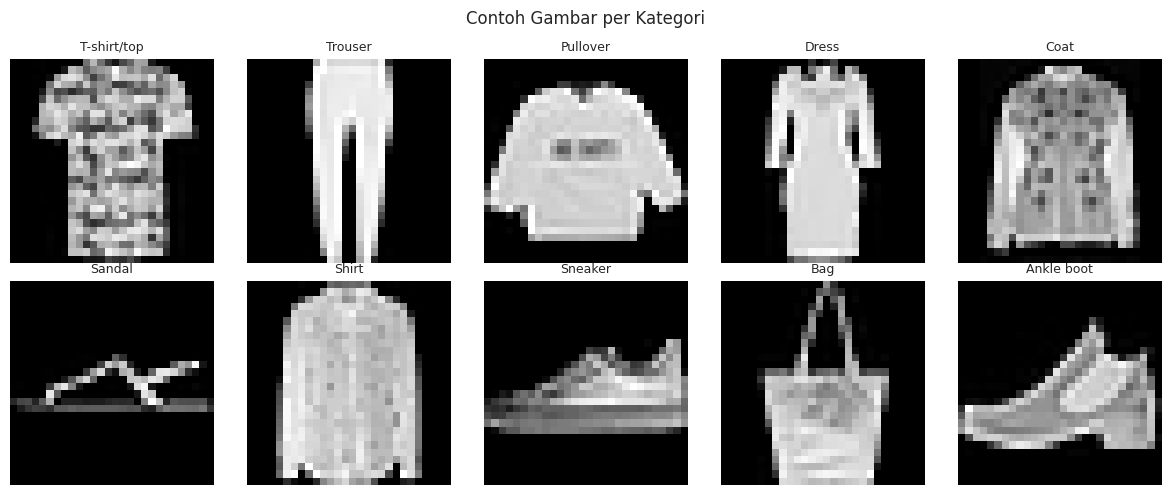

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(12, 5))
for i, ax in enumerate(axes.flat):
    row = df[df['label'] == i].iloc[0]
    image = row.drop('label').values.reshape(28, 28)
    ax.imshow(image, cmap='gray')
    ax.set_title(label_map[i], fontsize=9)
    ax.axis('off')
plt.suptitle("Contoh Gambar per Kategori")
plt.tight_layout()
plt.show()


# 7. Normalisasi

In [ ]:
X_full = df.drop(columns=['.......']).values.astype('float32') / 255.0
y_full = df['label'].values

print("Bentuk X_full:", X_full.shape)
print("Rentang nilai setelah normalisasi: min =", X_full.min(), ", max =", X_full.max())


Bentuk X_full: (10000, 784)
Rentang nilai setelah normalisasi: min = 0.0 , max = 1.0


## 8. Sampling Data (Stratified)

In [ ]:
N_SAMPLES = 4000

df_sample = (
    df.groupby('label', group_keys=False)
      .apply(lambda x: x.sample(int(N_SAMPLES / df['.........'].nunique()), random_state=RANDOM_STATE))
      .reset_index(drop=True)
)

print("Ukuran data sampel:", df_sample.shape)

X = df_sample.drop(columns=['label']).values.astype('float32') / 255.0
y = df_sample['label'].values

print("Bentuk X:", X.shape)
print("Bentuk y:", y.shape)


Ukuran data sampel: (4000, 785)
Bentuk X: (4000, 784)
Bentuk y: (4000,)


# 9. Reduksi Awal dengan PCA

In [ ]:
pca = PCA(n_components=50, random_state=.........(clue: diatas))
X_pca = pca.fit_transform(X)

print("Bentuk data setelah PCA:", ...........(mau mengetahui banyak data setelah pca))
print("Total variansi yang dijelaskan oleh 50 komponen ini: {:.2f}%".format(
    pca.explained_variance_ratio_.sum() * 100
))


Bentuk data setelah PCA: (4000, 50)
Total variansi yang dijelaskan oleh 50 komponen ini: 86.37%


# 10. Reduksi Dimensi dengan t-SNE

In [ ]:
tsne = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=RANDOM_STATE,
    verbose=1
)

X_tsne = tsne.fit_transform(......(di ambil dari mana))

print("Bentuk hasil t-SNE:", .......shape)


[t-SNE] Computing 91 nearest neighbors...
[t-SNE] Indexed 4000 samples in 0.004s...
[t-SNE] Computed neighbors for 4000 samples in 0.695s...
[t-SNE] Computed conditional probabilities for sample 1000 / 4000
[t-SNE] Computed conditional probabilities for sample 2000 / 4000
[t-SNE] Computed conditional probabilities for sample 3000 / 4000
[t-SNE] Computed conditional probabilities for sample 4000 / 4000
[t-SNE] Mean sigma: 1.667176
[t-SNE] KL divergence after 250 iterations with early exaggeration: 70.285881
[t-SNE] KL divergence after 1000 iterations: 1.124153
Bentuk hasil t-SNE: (4000, 2)


# 11. Visualisasi Hasil t-SNE

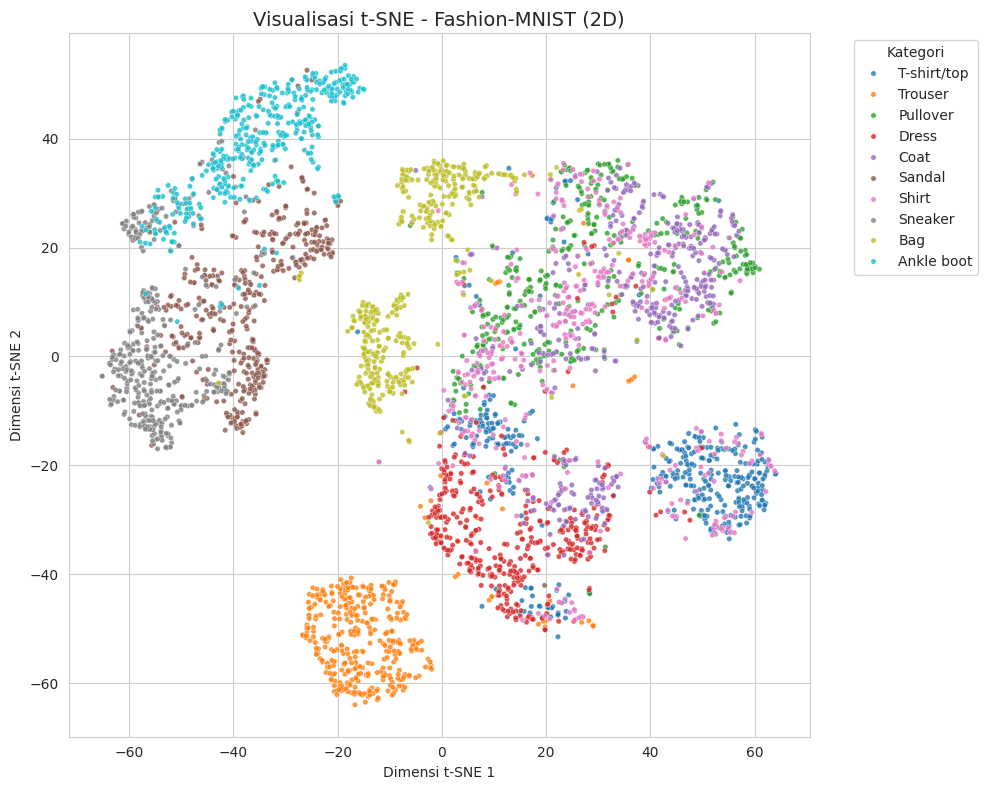

In [ ]:
plt.figure(figsize=(......., ....))

sns.scatterplot(
    x=X_tsne[:, 0],
    y=X_tsne[:, 1],
    hue=[label_map[label] for label in y],
    palette=sns.color_palette("tab10", 10),
    s=15,
    alpha=0.8
)

plt.title("Visualisasi t-SNE - Fashion-MNIST (2D)", fontsize=14)
plt.xlabel("Dimensi t-SNE 1")
plt.ylabel("Dimensi t-SNE 2")
plt.legend(title="Kategori", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()


# 12. Eksperimen Parameter Perplexity

In [ ]:
perplexities = [5, 20, 50, 100]

fig, axes = plt.subplots(1, len(perplexities), figsize=(22, 5))

for ax, perp in zip(axes, perplexities):
    tsne_exp = TSNE(
        n_components=2,
        perplexity=perp,
        learning_rate='auto',
        init='pca',
        random_state=RANDOM_STATE
    )
    X_exp = tsne_exp.fit_transform(X_pca)

    sns.scatterplot(
        x=X_exp[:, 0], y=X_exp[:, 1],
        hue=[label_map[label] for label in y],
        palette=sns.color_palette("tab10", 10),
        s=10, alpha=0.8, legend=False, ax=ax
    )
    ax.set_title(f"perplexity = {perp}")
    ax.set_xlabel("")
    ax.set_ylabel("")

plt.suptitle("Efek Parameter Perplexity terhadap Hasil t-SNE", fontsize=14)
plt.tight_layout()
plt.show()


# 13. Pembanding: t-SNE dengan PCA vs t-SNE Langsung (Tanpa PCA)



In [ ]:
import time

# --- Pendekatan 1: t-SNE dengan PCA dulu (784 -> 50 -> 2) ---
start_pca = time.time()

tsne_with_pca = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=RANDOM_STATE,
    verbose=0
)
X_tsne_with_pca = tsne_with_pca.fit_transform(X_pca)  # X_pca sudah dihitung di Bagian 9

waktu_dengan_pca = time.time() - start_pca
print(f"✅ t-SNE DENGAN PCA selesai dalam {waktu_dengan_pca:.2f} detik")


In [ ]:
# --- Pendekatan 2: t-SNE langsung dari data mentah (784 -> 2, tanpa PCA) ---
start_no_pca = time.time()

tsne_no_pca = TSNE(
    n_components=2,
    perplexity=30,
    learning_rate='auto',
    init='pca',
    random_state=RANDOM_STATE,
    verbose=0
)
X_tsne_no_pca = tsne_no_pca.fit_transform(X)  # X = data mentah 784 dimensi, hasil normalisasi (Bagian 8)

waktu_tanpa_pca = time.time() - start_no_pca
print(f"✅ t-SNE TANPA PCA selesai dalam {waktu_tanpa_pca:.2f} detik")


In [ ]:
print("Ringkasan Waktu Proses t-SNE")
print("-" * 40)
print(f"Dengan PCA (784 -> 50 -> 2) : {waktu_dengan_pca:.....(mau 2 angka dibelakang koma)} detik")
print(f"Tanpa PCA (784 -> 2 langsung): {waktu_tanpa_pca:.......(mau 2 angka dibelakang koma)} detik")
print("-" * 40)
selisih = waktu_tanpa_pca - waktu_dengan_pca
if selisih > 0:
    print(f"Tanpa PCA lebih lambat {selisih:2f} detik dibanding dengan PCA")
else:
    print(f"Tanpa PCA justru lebih cepat {abs(selisih):.2f} detik dibanding dengan PCA")


### Membandingkan Hasil Visualisasi Secara Berdampingan

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(18, 8))

sns.scatterplot(
    x=X_tsne_with_pca[:, 0], y=X_tsne_with_pca[:, 1],
    hue=[label_map[label] for label in ...],
    palette=sns.color_palette("tab10", 10),
    s=15, alpha=0.8, ax=axes[0], legend=False
)
axes[0].set_title(f"DENGAN PCA (50 dimensi)\nWaktu: {waktu_dengan_pca:.2f} detik", fontsize=12)
axes[0].set_xlabel("Dimensi t-SNE 1")
axes[0].set_ylabel("Dimensi t-SNE 2")

sns.scatterplot(
    x=X_tsne_no_pca[:, 0], y=X_tsne_no_pca[:, 1],
    hue=[label_map[label] for label in y],
    palette=sns.color_palette("tab10", .....),
    s=15, alpha=0.8, ax=axes[1]
)
axes[1].set_title(f"TANPA PCA (784 dimensi langsung)\nWaktu: {waktu_tanpa_pca:.2f} detik", fontsize=12)
axes[1].set_xlabel("Dimensi t-SNE 1")
axes[1].set_ylabel("Dimensi t-SNE 2")
axes[1].legend(title="Kategori", bbox_to_anchor=(1.05, 1), loc='upper left')

plt.suptitle("Perbandingan t-SNE: Dengan PCA vs Tanpa PCA", fontsize=15)
plt.tight_layout()
plt.show()
